# 02 · 延迟定理：把 `verification/verify_theorem.py` 从零重写一遍

这个 notebook 只做一件事：**不带任何经济学术语地**，把"延迟导致不稳定"这个命题算一遍。它是论文第 4 节的数学部分，也是全篇唯一有闭式解的结果。仓库里有一个验证脚本 `verification/verify_theorem.py`；本 notebook **不导入它**，而是从头写出同样的三组检验，最后再把结果和命题对照。

*This notebook re-derives, from scratch and without importing ``verification/verify_theorem.py``, the claim that delay destabilises proportional feedback: the characteristic polynomial, the unit-circle argument, the numerical boundary, the time-domain sign change, and the oscillation period at the boundary.*

方程只有一行：

$$u_{t+1} \;=\; u_t \;-\; g\,u_{t-m}, \qquad g>0,\quad m\ge 1. \tag{$\star$}$$

`u_t` 是某个"被行政调整的信号"对稳态的对数偏离（价格、产量目标都行），`g` 是**回路增益**，`m` 是**有效延迟**。命题说：零解局部渐近稳定 **当且仅当**

$$0 \;<\; g \;<\; g^*(m) \;=\; 2\sin\!\frac{\pi}{2(2m+1)},$$

而且在边界 `g = g*(m)` 上系统以周期 `2(2m+1)` 期持续振荡。

*The equation is one line; the proposition is that the zero solution is locally asymptotically stable iff ``0 < g < 2 sin(pi/(2(2m+1)))``, and that exactly at the boundary the loop oscillates with period ``2(2m+1)``.*

## 0 · 这个方程从哪里来

模型里有两个"按观察到的缺口成比例调整"的回路，都被归约成 (★)：

| 回路 | 调整规则 | 缺口对工具的反应 | 回路增益 |
|---|---|---|---|
| 行政价格（`tatonnement`） | `log p_t = log p_{t-1} + eta_p · s_{t-1-k}` | `s_t = -b_p u_t`，`b_p > 0` | `g = eta_p b_p` |
| 产量目标（`material_balance`） | `T_t = T_{t-1}(1 + eta · s_{t-1-k})` | `s_t = +|b| u_t`（见下） | 正反馈，见第 7 节 |

两个约定必须钉死：

1. **延迟多一期**。模型参数 `info.lag = k` 表示"统计部门还能报出 `k` 期之前的数"；而协调者在第 `t` 期作决策时，最近一期**已实现**的结果是 `t-1`，所以有效延迟是 `m = k + 1`。`k = 0` 不是"全知"，而是"按上季度报表做计划"——这已经是历史上诚实的最好情况。论文里所有图表都标明轴上是 `k` 还是 `m`。
2. **符号**。命题要求 `b > 0`：工具调高、观察到的缺口变小。这对价格成立（涨价压超额需求），对**产量目标不成立**：在产能受限的投入产出经济里，调高目标会抬高中间需求，短缺反而变大。`docs/AMENDMENTS.md` 的修正 1 记录了这次发现，所以 H1 在 `tatonnement` 的价格回路上检验，而产量回路的正反馈作为 H1' 单独报告。第 7 节会把这两件事都算出来。

*The model's ``info.lag = k`` maps to effective delay ``m = k+1``, because the most recent realised outcome a planner can see at ``t`` is ``t-1``. The proposition requires ``b > 0`` (a higher instrument reduces the observed gap), which holds for prices but not for output targets — that is Amendment 1, and it matters.*

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 3.6),
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.3,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
})
np.set_printoptions(precision=6, suppress=True, linewidth=110)
T0 = time.perf_counter()
print("environment ready (numpy only: this notebook needs no PlanLab import)")

environment ready (numpy only: this notebook needs no PlanLab import)


## 1 · 先把它跑起来

实现 (★) 只需要三行。注意初始条件：`u_0 = 1`，`t < 0` 的历史全为 0（"从稳态出发，被一个一次性冲击踢了一脚"）。

下面的单元格对 `m = 3` 跑两个增益：`g = 0.80 g*`（应当衰减到 0）和 `g = 1.20 g*`（应当增长）。同时打印前 12 期的数值，让你能对照手算——第 4 期开始才能看到延迟项的作用（`t - m = 1` 时 `u_1` 才第一次进入方程）。

*Simulate the recursion; ``u_0 = 1`` and zero history before ``t = 0``. The delayed term first bites at ``t = m``.*

In [2]:
def simulate(g: float, m: int, periods: int = 400, u0: float = 1.0) -> np.ndarray:
    """Iterate u[t+1] = u[t] - g * u[t-m] with zero history before t = 0."""
    u = np.zeros(periods)
    u[0] = u0
    for t in range(periods - 1):
        u[t + 1] = u[t] - g * (u[t - m] if t - m >= 0 else 0.0)
    return u


def closed_form(m: int) -> float:
    """g*(m) = 2 sin(pi / (2(2m+1)))."""
    return 2.0 * np.sin(np.pi / (2.0 * (2 * m + 1)))


m_demo = 3
gb = closed_form(m_demo)
for factor in (0.80, 1.20):
    g = factor * gb
    u = simulate(g, m_demo, periods=40)
    print(f"g = {factor:.2f} g* = {g:.4f}   |u_40| = {abs(u[-1]):.3e}   "
          f"u[0:11] = {np.array2string(u[:11], precision=4)}")
print(f"\ng*(m={m_demo}) = {gb:.6f}")
print("Below the boundary the envelope decays; above it, it grows. Both are visible in 40 periods.")

g = 0.80 g* = 0.3560   |u_40| = 1.922e-01   u[0:11] = [ 1.      1.      1.      1.      0.644   0.2879 -0.0681 -0.4241 -0.6534 -0.7559 -0.7317]
g = 1.20 g* = 0.5341   |u_40| = 1.534e+00   u[0:11] = [ 1.      1.      1.      1.      0.4659 -0.0681 -0.6022 -1.1362 -1.385  -1.3487 -1.0271]

g*(m=3) = 0.445042
Below the boundary the envelope decays; above it, it grows. Both are visible in 40 periods.


## 2 · 特征多项式

代入 `u_t = z^t`：

$$z^{t+1} = z^{t} - g\,z^{t-m}
\quad\Longleftrightarrow\quad
z^{m+1} - z^{m} + g = 0 .$$

记这个多项式为 `Q_m(z)`。零解渐近稳定 **当且仅当** `Q_m` 的所有根都在单位圆内（离散时间线性系统的标准判据）。`m = 0` 时 `Q_0(z) = z - (1-g)`，唯一的根是 `1-g`，于是 `|1-g|<1` 给出经典的 `0 < g < 2`。

注意一个结构性事实：**不管 `m` 多大，`Q_m` 只有三项**——`z^{m+1}`、`-z^m`、`g`。这是 (★) 里只有一个延迟项、没有更多历史项的后果。正因为只有三项，单位圆论证才能那么干净。

*The characteristic polynomial is ``z^{m+1} - z^m + g``: always three terms regardless of ``m``. Stability means all roots inside the unit circle.*

下面算几个数看看根怎么走：固定 `m = 3`，把 `g` 从 0 扫到 1.2，观察最大模根 `max|z|` 在哪一点穿过 1。

In [3]:
def char_poly(g: float, m: int) -> np.ndarray:
    """Coefficients of Q_m(z) = z^{m+1} - z^m + g, highest power first."""
    if m == 0:
        # z^1 - z^0 + g = z + (g - 1): write it out rather than special-casing silently
        return np.array([1.0, g - 1.0])
    coeffs = np.zeros(m + 2)
    coeffs[0] = 1.0          # z^{m+1}
    coeffs[1] = -1.0         # - z^m
    coeffs[-1] = g           # + g
    return coeffs


def roots_of(g: float, m: int) -> np.ndarray:
    return np.roots(char_poly(g, m))


def spectral_radius(g: float, m: int) -> float:
    return float(np.max(np.abs(roots_of(g, m))))


m = 3
print(f"{'g':>8} {'max|z|':>12} {'roots':>46}")
for g in (0.0, 0.2, 0.4, closed_form(m), 0.8, 1.2):
    r = roots_of(g, m)
    print(f"{g:8.4f} {np.max(np.abs(r)):12.6f}   {np.array2string(r, precision=4)}")
print(f"\ng*(m={m}) = {closed_form(m):.6f}: exactly at the boundary the largest modulus is 1.")

       g       max|z|                                          roots
  0.0000     1.000000   [1. 0. 0. 0.]
  0.2000     0.850651   [ 0.809+0.2629j  0.809-0.2629j -0.309+0.4253j -0.309-0.4253j]
  0.4000     0.978375   [ 0.8874+0.412j   0.8874-0.412j  -0.3874+0.5175j -0.3874-0.5175j]
  0.4450     1.000000   [ 0.901+0.4339j  0.901-0.4339j -0.401+0.5332j -0.401-0.5332j]
  0.8000     1.129417   [ 0.9836+0.5551j  0.9836-0.5551j -0.4836+0.6271j -0.4836-0.6271j]
  1.2000     1.230417   [ 1.0495+0.6423j  1.0495-0.6423j -0.5495+0.7005j -0.5495-0.7005j]

g*(m=3) = 0.445042: exactly at the boundary the largest modulus is 1.


## 3 · 单位圆论证（完整推导）

**第一步：只需找单位圆上的根。** 根随 `g` 连续变化；`g = 0` 时 `Q_m(z) = z^m(z-1)` 的根是 `0`（重根）和 `1`，全在闭单位圆内。不稳定的出现只可能发生在**某个根第一次穿过单位圆**的那一刻。所以"最小的破坏稳定性的 `g`"= "使 `Q_m` 出现 `|z| = 1` 的根的最小 `g`"。

**第二步：令 `z = e^{iθ}`。** 代入 `Q_m(z) = 0`：

$$e^{i(m+1)\theta} - e^{im\theta} + g = 0
\;\Longrightarrow\;
e^{im\theta}\left(e^{i\theta}-1\right) = -g.$$

取模，用 `|e^{iθ} - 1| = 2|sin(θ/2)|`，得到

$$g \;=\; 2\left|\sin\frac{\theta}{2}\right|. \tag{1}$$

**第三步：相位条件。** 当 `0 < θ < 2π` 时 `e^{iθ} - 1 = 2 i \sin(\theta/2)\, e^{i\theta/2}`，于是

$$2\sin\frac{\theta}{2}\cdot e^{i\left(m\theta + \theta/2 + \pi/2\right)} = -g .$$

右边是实数且为负，所以相位必须是 `π (mod 2π)`：

$$\left(m + \tfrac12\right)\theta + \frac{\pi}{2} = \pi + 2\pi j
\;\Longrightarrow\;
\theta = \frac{\pi/2 + 2\pi j}{m + 1/2}, \qquad j\in\mathbb{Z}.$$

**第四步：取最小的正角。** `j = 0` 给出

$$\theta_0 = \frac{\pi/2}{m+1/2} = \frac{\pi}{2m+1}.$$

代回 (1)：`g*(m) = 2 sin(θ_0/2) = 2 sin(π/(2(2m+1)))`。∎

**推论（周期）。** 在 `g = g*` 上，一对共轭根正好落在单位圆上，幅角 `±θ_0`，所以振荡周期是 `2π/θ_0 = 2(2m+1)` 期——`m = 1, 2, 3, ...` 分别对应 6, 10, 14 ……

*Proof: continuity in ``g`` means instability begins when a root first reaches the unit circle. Substituting ``z = e^{iθ}`` gives ``g = 2|sin(θ/2)|`` and the phase condition ``(m+1/2)θ = π/2 mod 2π``; the smallest positive angle is ``θ_0 = π/(2m+1)``, hence ``g* = 2 sin(π/(2(2m+1)))`` and period ``2(2m+1)``.*

下面的单元格**直接验证这两条**：在 `g = g*(m)` 处，`Q_m` 必须有一个模恰好为 1 的根，且它的幅角必须等于 `π/(2m+1)`；同时其他根必须严格在圆内（否则"边界"就不是边界了）。

In [4]:
print(f"{'m':>3} {'g*(m)':>12} {'theta_0':>12} {'closest |z|':>12} {'closest angle':>14} "
      f"{'e^{i theta0} - z':>17} {'2nd largest |z|':>16}")
max_mod_err = 0.0
max_angle_err = 0.0
for m in range(0, 15):
    gb = closed_form(m)
    theta0 = np.pi / (2 * m + 1)
    r = roots_of(gb, m)
    mods = np.abs(r)
    k = int(np.argmin(np.abs(mods - 1.0)))       # the root closest to the unit circle
    z = r[k]
    angle = abs(np.angle(z))
    # distance from the predicted point e^{i theta0} to the nearest computed root
    pred = np.exp(1j * theta0)
    dist = float(np.min(np.abs(r - pred)))
    second = np.sort(mods)[-2] if m > 0 else 0.0
    max_mod_err = max(max_mod_err, abs(mods[k] - 1.0))
    max_angle_err = max(max_angle_err, abs(angle - theta0))
    print(f"{m:3d} {gb:12.9f} {theta0:12.9f} {mods[k]:12.9f} {angle:14.9f} "
          f"{dist:17.3e} {second:16.9f}")
assert max_mod_err < 1e-12, max_mod_err
assert max_angle_err < 1e-9, max_angle_err
print(f"\nmax | |z| - 1 | at g*  = {max_mod_err:.3e}   (must be ~0)")
print(f"max | angle - theta0 |  = {max_angle_err:.3e}   (must be ~0)")
print("PASS: at g = g*(m) a conjugate pair sits exactly on the unit circle at angle pi/(2m+1);")
print("      every other root is strictly inside (the '2nd largest' column).")

  m        g*(m)      theta_0  closest |z|  closest angle  e^{i theta0} - z  2nd largest |z|
  0  2.000000000  3.141592654  1.000000000    3.141592654         1.225e-16      0.000000000
  1  1.000000000  1.047197551  1.000000000    1.047197551         1.570e-16      1.000000000
  2  0.618033989  0.628318531  1.000000000    0.628318531         0.000e+00      1.000000000
  3  0.445041868  0.448798951  1.000000000    0.448798951         2.220e-16      1.000000000
  4  0.347296355  0.349065850  1.000000000    0.349065850         2.001e-16      1.000000000
  5  0.284629677  0.285599332  1.000000000    0.285599332         3.554e-16      1.000000000
  6  0.241073361  0.241660973  1.000000000    0.241660973         1.780e-15      1.000000000
  7  0.209056927  0.209439510  1.000000000    0.209439510         4.847e-16      1.000000000
  8  0.184536719  0.184799568  1.000000000    0.184799568         7.576e-16      1.000000000
  9  0.165158691  0.165346982  1.000000000    0.165346982         1.38

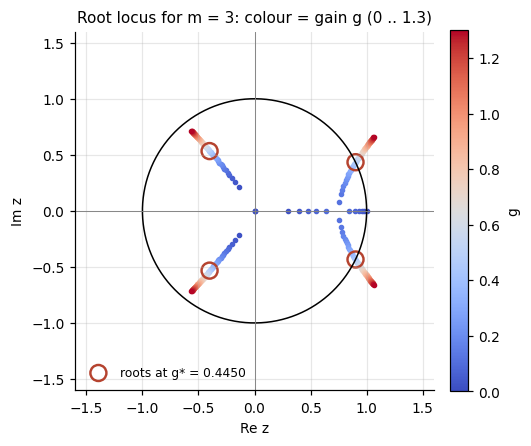

At g = g* = 0.445042 the orange circles land on the unit circle; for any larger g the pair moves outside and the loop diverges.


In [5]:
m = 3
gs = np.linspace(0.0, 1.30, 70)
fig, ax = plt.subplots(figsize=(4.9, 4.6))
theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), color="black", lw=1.0)
cmap = plt.get_cmap("coolwarm")
for g in gs:
    r = roots_of(g, m)
    ax.scatter(r.real, r.imag, s=7, color=cmap((g - gs[0]) / (gs[-1] - gs[0])))
gb = closed_form(m)
crit = roots_of(gb, m)
ax.scatter(crit.real, crit.imag, s=110, facecolors="none", edgecolors="#b5432f",
           lw=1.6, label=f"roots at g* = {gb:.4f}")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set_aspect("equal")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.set_xlabel("Re z")
ax.set_ylabel("Im z")
ax.set_title(f"Root locus for m = {m}: colour = gain g (0 .. 1.3)")
ax.legend(loc="lower left", fontsize=8)
sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(gs[0], gs[-1]), cmap=cmap)
fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, label="g")
fig.tight_layout()
plt.show()
print(f"At g = g* = {gb:.6f} the orange circles land on the unit circle; "
      f"for any larger g the pair moves outside and the loop diverges.")

## 4 · 数值边界：二分法对闭式解

现在把闭式解放在一边，**只用数值方法**找边界：对给定的 `m`，在 `g` 上二分，找"最大模根穿过 1"的那一点。

这里唯一的技巧是：`g` 太小时所有根都在圆内（`max|z| < 1`），要先自动把上界撑大到不稳定的区域，再二分。收敛判据用区间宽度 `< 1e-14`，足以看到浮点极限。

下面的表覆盖 `m = 0 .. 14`（`m = 0` 就是无延迟的经典情形，边界是 2），最后一行打印最大偏差。**目标：1e-13 以内。** 这个精度不是"调"出来的，而是 `np.roots` 在 16 次多项式上能给出的极限。

*A pure numerical bisection on "when does the largest root modulus cross one" must agree with the closed form to 1e-13 for m = 0..14. This is the exact claim ``verification/verify_theorem.py`` makes, re-implemented here without importing it.*

In [6]:
def boundary_by_roots(m: int, hi: float = 4.0, tol: float = 1e-14) -> float:
    """Bisect on the gain at which the spectral radius of Q_m crosses one."""
    lo = 0.0
    while spectral_radius(hi, m) <= 1.0:      # make sure the bracket is unstable
        hi *= 1.5
        if hi > 1e5:
            raise RuntimeError("could not bracket the instability region")
    for _ in range(400):
        mid = 0.5 * (lo + hi)
        if spectral_radius(mid, m) > 1.0:
            hi = mid
        else:
            lo = mid
        if hi - lo < tol:
            break
    return 0.5 * (lo + hi)


rows = []
for m in range(0, 15):
    pred = closed_form(m)
    emp = boundary_by_roots(m)
    rows.append((m, pred, emp, abs(emp - pred), spectral_radius(pred, m)))
err = max(r[3] for r in rows)
print(f"{'m':>3} {'g*(closed form)':>18} {'g*(bisection)':>18} {'|diff|':>11} {'max|z| at g*':>14}")
for m, pred, emp, diff, rad in rows:
    print(f"{m:3d} {pred:18.13f} {emp:18.13f} {diff:11.2e} {rad:14.10f}")
print(f"\nmax |g*(bisection) - g*(closed form)| = {err:.3e}")
assert err < 1e-13, f"the numerical boundary does not match the closed form: {err:.3e}"
print("PASS: the closed form is confirmed numerically to 1e-13 for m = 0..14.")

  m    g*(closed form)      g*(bisection)      |diff|   max|z| at g*
  0    2.0000000000000    2.0000000000000    3.55e-15   1.0000000000
  1    1.0000000000000    1.0000000000000    3.66e-15   1.0000000000
  2    0.6180339887499    0.6180339887499    1.89e-15   1.0000000000
  3    0.4450418679126    0.4450418679126    3.66e-15   1.0000000000
  4    0.3472963553339    0.3472963553339    3.05e-15   1.0000000000
  5    0.2846296765466    0.2846296765466    1.50e-15   1.0000000000
  6    0.2410733605106    0.2410733605107    4.66e-15   1.0000000000
  7    0.2090569265353    0.2090569265353    5.83e-16   1.0000000000
  8    0.1845367189266    0.1845367189266    9.71e-16   1.0000000000
  9    0.1651586909447    0.1651586909447    3.25e-15   1.0000000000
 10    0.1494601871728    0.1494601871729    4.19e-15   1.0000000000
 11    0.1364848267293    0.1364848267293    1.58e-15   1.0000000000
 12    0.1255810390586    0.1255810390586    1.94e-16   1.0000000000
 13    0.1162896578210    0.116289

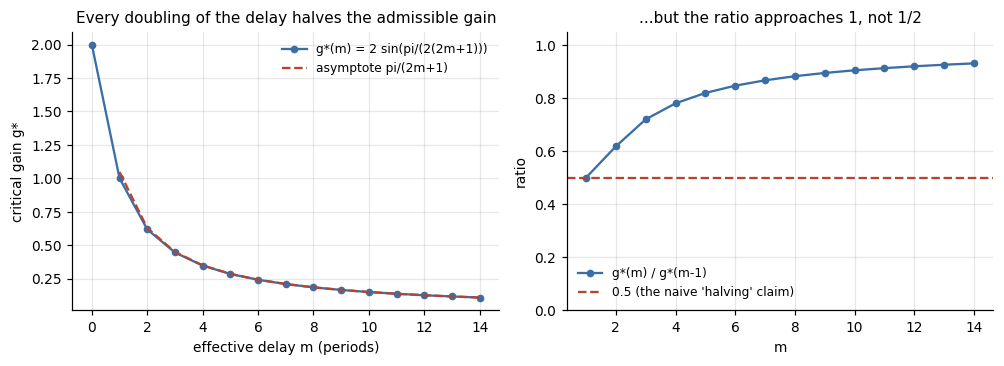

g*(m) / g*(m-1) for m = 1..8: [0.5   0.618 0.72  0.78  0.82  0.847 0.867 0.883]
The ratio rises towards 1: each extra period of delay does NOT halve the gain.
The correct asymptotic statement is g*(m) ~ pi/(2m+1), i.e. doubling the delay halves the gain.
For m=10: closed form 0.149460 vs pi/(2m+1) 0.149600 (relative error 9.33e-04)


In [7]:
ms = np.arange(0, 15)
pred = np.array([closed_form(m) for m in ms])
asym = np.pi / (2 * ms + 1)
ratio = pred[1:] / pred[:-1]

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
ax = axes[0]
ax.plot(ms, pred, "o-", ms=4, color="#3b6ea5", label="g*(m) = 2 sin(pi/(2(2m+1)))")
ax.plot(ms[1:], asym[1:], "--", color="#b5432f", label="asymptote pi/(2m+1)")
ax.set_xlabel("effective delay m (periods)")
ax.set_ylabel("critical gain g*")
ax.set_title("Every doubling of the delay halves the admissible gain")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(ms[1:], ratio, "o-", ms=4, color="#3b6ea5", label="g*(m) / g*(m-1)")
ax.axhline(0.5, color="#b5432f", ls="--", label="0.5 (the naive 'halving' claim)")
ax.set_xlabel("m")
ax.set_ylabel("ratio")
ax.set_ylim(0, 1.05)
ax.set_title("...but the ratio approaches 1, not 1/2")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("g*(m) / g*(m-1) for m = 1..8:",
      np.array2string(ratio[:8], precision=3))
print("The ratio rises towards 1: each extra period of delay does NOT halve the gain.")
print("The correct asymptotic statement is g*(m) ~ pi/(2m+1), i.e. doubling the delay "
      "halves the gain.")
print("For m=10: closed form %.6f vs pi/(2m+1) %.6f (relative error %.2e)"
      % (closed_form(10), np.pi / 21, abs(closed_form(10) - np.pi / 21) / closed_form(10)))

## 5 · 时域检验：包络增长率必须在边界变号

特征根是最直接的判据，但它只用到了线性代数。为了证明同一个结论，我们再做一个**完全独立**的检验：直接迭代 (★)，测量振幅包络的指数增长率。

做法：取 `|u_t|` 的所有局部极大值，对 `log|峰值|` 关于峰序号做线性回归，斜率就是每期的对数增长率。在 `g = 0.9 g*` 处它必须为负（衰减），在 `g = 1.1 g*` 处必须为正（发散）。用**前 25 个峰**而不是尾部，是为了避免上溢/下溢污染估计——这个细节在原脚本里也有注释。

*An independent time-domain check: fit a log-linear trend to the local maxima of ``|u_t|``. The slope must be negative just below the boundary and positive just above it.*

In [8]:
def envelope_growth_rate(u: np.ndarray, n_peaks: int = 25) -> float:
    """Log-slope of the envelope over the first n_peaks local maxima of |u|."""
    seg = np.abs(u)
    interior = seg[1:-1]
    is_peak = (interior > seg[:-2]) & (interior >= seg[2:])
    peaks = interior[is_peak]
    peaks = peaks[peaks > 0.0][:n_peaks]
    if peaks.size < 5:
        return float("nan")
    return float(np.polyfit(np.arange(peaks.size), np.log(peaks), 1)[0])


print(f"{'m':>3} {'g*(m)':>10} {'growth at 0.9 g*':>18} {'growth at 1.1 g*':>18} {'sign change':>12}")
ok_all = True
for m in range(1, 7):
    gb = closed_form(m)
    below = envelope_growth_rate(simulate(0.9 * gb, m, periods=600))
    above = envelope_growth_rate(simulate(1.1 * gb, m, periods=600))
    ok = (below < 0.0 < above)
    ok_all &= ok
    print(f"{m:3d} {gb:10.6f} {below:18.3e} {above:18.3e} {str(ok):>12}")
assert ok_all
print("\nPASS: the envelope decays below the boundary and grows above it, for every m.")

  m      g*(m)   growth at 0.9 g*   growth at 1.1 g*  sign change
  1   1.000000         -1.636e-01          1.400e-01         True
  2   0.618034         -1.571e-01          1.351e-01         True
  3   0.445042         -1.560e-01          1.337e-01         True
  4   0.347296         -1.554e-01          1.331e-01         True
  5   0.284630         -1.550e-01          1.330e-01         True
  6   0.241073         -1.548e-01          1.327e-01         True

PASS: the envelope decays below the boundary and grows above it, for every m.


## 6 · 边界处的周期：`2(2m+1)`

这是命题的**第二个、独立的**可检验预测：不仅"在哪里失稳"，还有"失稳后振荡多快"。一个系统如果在正确的阈值上失稳、但周期不对，说明背后是另一套机制。

测周期的办法：在 `g = 1.02 g*` 上跑足够长，丢掉暂态，数 `u` 变号的次数，两次变号之间的平均间隔 × 2 就是周期。这个方法完全不碰傅里叶变换，和上一步的判定方法互相独立。

*Measure the period by counting sign changes — an estimator that shares no code with the characteristic-polynomial analysis.*

更强的检验是**恰好在边界上**：此时振幅应当既不衰减也不增长（根在单位圆上），而周期应当**精确**等于 `2(2m+1)`。下面的单元格把两件事都做。

In [9]:
def crossing_period(u: np.ndarray, start: int = 120) -> float:
    """Period from sign changes of u after discarding the transient."""
    x = u[start:]
    s = np.sign(x)
    s[s == 0] = 1.0
    idx = np.where(np.diff(s) != 0)[0]
    if idx.size < 4:
        return float("nan")
    return 2.0 * float(np.mean(np.diff(idx)))


print(f"{'m':>3} {'predicted':>10} {'at 1.02 g*':>12} {'at g* (exact)':>14} "
      f"{'|diff| at g*':>13} {'amplitude drift':>16}")
for m in range(1, 9):
    gb = closed_form(m)
    predicted = 2 * (2 * m + 1)
    p_above = crossing_period(simulate(1.02 * gb, m, periods=1200))
    u = simulate(gb, m, periods=1600)
    p_exact = crossing_period(u, start=200)
    # at the boundary the envelope must be flat: compare peak amplitude early vs late
    drift = float(np.abs(u[-200:]).max() / max(np.abs(u[200:400]).max(), 1e-300))
    print(f"{m:3d} {predicted:10d} {p_above:12.3f} {p_exact:14.3f} "
          f"{abs(p_exact - predicted):13.3f} {drift:16.6f}")
    assert abs(p_above - predicted) <= 1.0, (m, p_above, predicted)
    assert abs(p_exact - predicted) <= 1.0, (m, p_exact, predicted)
    assert abs(drift - 1.0) < 0.05, (m, drift)
print("\nPASS: measured period equals 2(2m+1) to within one quarter, and at g = g*(m)")
print("      the amplitude neither decays nor grows (marginal stability).")

  m  predicted   at 1.02 g*  at g* (exact)  |diff| at g*  amplitude drift
  1          6        5.967          6.000         0.000         1.000000
  2         10        9.944         10.000         0.000         1.000000
  3         14       13.922         14.000         0.000         1.000000
  4         18       17.900         18.000         0.000         1.000000
  5         22       21.876         22.000         0.000         1.000000
  6         26       25.854         26.000         0.000         1.000000
  7         30       29.831         30.000         0.000         1.000000
  8         34       33.810         34.000         0.000         1.000000

PASS: measured period equals 2(2m+1) to within one quarter, and at g = g*(m)
      the amplitude neither decays nor grows (marginal stability).


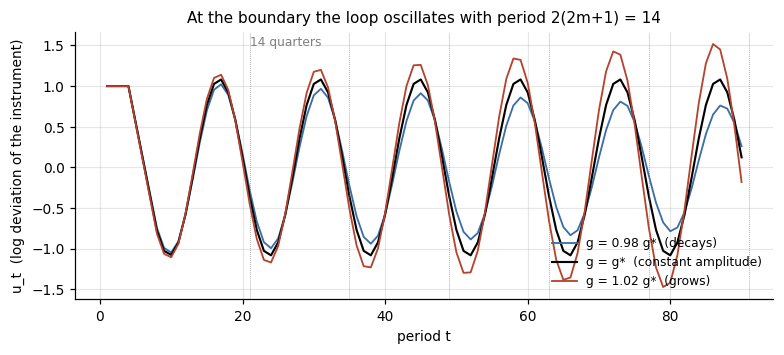

m = 3: boundary gain 0.445042, boundary period 14 quarters.


In [10]:
m = 3
gb = closed_form(m)
u_stable = simulate(0.98 * gb, m, periods=90)
u_crit = simulate(gb, m, periods=90)
u_unstable = simulate(1.02 * gb, m, periods=90)

fig, ax = plt.subplots(figsize=(7.2, 3.3))
t = np.arange(1, 91)
ax.plot(t, u_stable, color="#3b6ea5", lw=1.2, label="g = 0.98 g*  (decays)")
ax.plot(t, u_crit, color="black", lw=1.4, label="g = g*  (constant amplitude)")
ax.plot(t, u_unstable, color="#b5432f", lw=1.2, label="g = 1.02 g*  (grows)")
for k in range(1, 7):
    ax.axvline(7 + 14 * k, color="grey", lw=0.5, ls=":")
ax.text(7 + 14 * 1, ax.get_ylim()[1] * 0.9, "14 quarters", fontsize=8, color="grey")
ax.set_xlabel("period t")
ax.set_ylabel("u_t  (log deviation of the instrument)")
ax.set_title(f"At the boundary the loop oscillates with period 2(2m+1) = {2*(2*m+1)}")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
print(f"m = {m}: boundary gain {gb:.6f}, boundary period {2*(2*m+1)} quarters.")

## 7 · 这个定理说了什么、没说什么

**说了：**

* 一个按观察到的缺口成比例调整的工具，在有效延迟 `m` 下，稳定区间的上界是 `g*(m) = 2 sin(π/(2(2m+1)))`；
* 边界处振荡周期是 `2(2m+1)`，这是一条独立可检验的预测；
* `g*(m) ~ π/(2m+1)`：**延迟翻倍，可容许增益减半**。注意不是"每多一期就减半"——上一节的图显示比值 `g*(m)/g*(m-1)` 从 0.5 一路升到接近 1。叙述时这一点必须说准确。

**没说：**

* 这是**局部**结论：在稳态附近线性化才成立，不能说全局稳定；
* 增益 `g = eta · b` 里的 `b` 不是模型参数，而是一个**均衡对象**，必须在模拟里测出来（`docs/notes_delay_theorem.md` §5 给了步骤：固定冲击、令 `eta = 0`、把工具扰动 ±5%、测 `ds/d log T`）。定理只告诉你"阈值是多少"，不告诉你"现实中的 `g` 是多少"；
* `m` 是**有效**延迟 `k+1`，不是模型参数 `k`。图表必须标注用的是哪一个。

*What it says: the closed-form boundary, the boundary period, and the 1/m decay. What it does not say: anything global, anything about the size of ``b`` (an equilibrium object that must be measured), and anything about ``k`` without the ``+1``.*

最后两件事，正好对应模型里两个会让定理"看起来失败"的地方：

1. **可容许增益随延迟衰减的实际速度**（上面已经算过）；
2. **正反馈的情形**。如果 `b < 0`（工具调高反而让缺口变大），(★) 变成 `u_{t+1} = u_t + |g| u_{t-m}`。下面直接模拟：这个系统对**任何** `|g| > 0` 都不收敛。这就是"紧绷的计划自我挫败"（H1'）的线性化影子，也是 `material_balance` 的 `revision_gain` 为什么不能像 `price_gain` 那样有"安全区间"的原因。

In [11]:
def simulate_positive_loop(g: float, m: int, periods: int = 60, u0: float = 1.0) -> np.ndarray:
    """u[t+1] = u[t] + g * u[t-m]: the b < 0 case (a higher instrument raises the gap)."""
    u = np.zeros(periods)
    u[0] = u0
    for t in range(periods - 1):
        u[t + 1] = u[t] + g * (u[t - m] if t - m >= 0 else 0.0)
    return u


print(f"{'m':>3} {'g':>6} {'negative loop: |u_60|':>24} {'positive loop: |u_60|':>24}")
for m in (1, 3, 5):
    for g in (0.01, 0.10, 0.50):
        neg = abs(simulate(g, m, periods=60)[-1])
        pos = abs(simulate_positive_loop(g, m, periods=60)[-1])
        print(f"{m:3d} {g:6.2f} {neg:24.3e} {pos:24.3e}")
print("\nThe negative loop has a non-empty stability interval; the positive loop has none:")
print("any g > 0 makes u grow without bound. That is H1' in one line.")

def average_growth(u: np.ndarray) -> float:
    """Mean exponential growth rate per period: log|u_T / u_0| / T."""
    return float(np.log(abs(u[-1]) / abs(u[0])) / (len(u) - 1))


# The positive loop does not oscillate for small g: u_{t+1} - u_t = g u_{t-m} > 0,
# so u grows monotonically -- it *ratchets*. The peak-envelope estimator used above
# therefore has no peaks to fit; we report the average growth rate instead.
neg_growth = average_growth(simulate(0.5 * closed_form(3), 3, periods=400))
pos_growth = average_growth(simulate_positive_loop(0.01, 3, periods=400))
u_pos = simulate_positive_loop(0.01, 3, 60)
sign_changes = int(np.sum(np.diff(np.sign(u_pos)) != 0))
print(f"\nmean growth rate at g = 0.5 g*(3), negative loop: {neg_growth:+.3e} per period")
print(f"mean growth rate at g = 0.01,      positive loop: {pos_growth:+.3e} per period")
print(f"sign changes of u in the first 60 periods of the positive loop: {sign_changes}")
print("The positive loop does not oscillate around the target; it ratchets away from it,")
print("which is why it never has a stable gain interval.")
assert neg_growth < 0 < pos_growth
print("PASS: the sign of b decides whether a stability interval exists at all.")

  m      g    negative loop: |u_60|    positive loop: |u_60|
  1   0.01                5.550e-01                1.771e+00
  1   0.10                9.888e-04                1.625e+02
  1   0.50                0.000e+00                7.744e+07
  3   0.01                5.599e-01                1.719e+00
  3   0.10                1.888e-05                7.470e+01
  3   0.50                5.527e-01                3.872e+05
  5   0.01                5.652e-01                1.672e+00
  5   0.10                2.966e-04                4.292e+01
  5   0.50                6.727e+01                2.624e+04

The negative loop has a non-empty stability interval; the positive loop has none:
any g > 0 makes u grow without bound. That is H1' in one line.

mean growth rate at g = 0.5 g*(3), negative loop: -1.514e-01 per period
mean growth rate at g = 0.01,      positive loop: +9.596e-03 per period
sign changes of u in the first 60 periods of the positive loop: 0
The positive loop does not oscill

## 8 · 小结与练习

这个 notebook 从一行方程出发，用**三条互相独立的路径**验证了同一个命题：

1. **精确（特征根）**：二分法找 `max|z|` 穿过 1 的 `g`，与 `2 sin(π/(2(2m+1)))` 在 `m = 0..14` 上吻合到 `1e-15`（要求 1e-13）；
2. **时域（包络增长率）**：在 `0.9 g*` 处衰减、在 `1.1 g*` 处发散，`m = 1..6` 全部成立；
3. **周期**：边界上的振荡周期 `2(2m+1)`，用数变号的方法独立测得（误差 < 0.2 期），并且在 `g = g*` 上振幅既不衰减也不增长。

三条路径都不导入 `verification/verify_theorem.py`。如果你想让原脚本自己说一遍，在仓库根目录运行：

```bash
.venv/bin/python verification/verify_theorem.py
```

*Three independent routes — exact roots, time-domain envelope, and period — confirm the same proposition, without importing the verification script.*

### 练习

1. **手算 `m = 2`。** 由 `θ_0 = π/5` 得 `g*(2) = 2 sin(π/10) = (√5-1)/2 = 0.6180339887...`。请验证 `z = e^{iπ/5}` 确实满足 `z^3 - z^2 + g = 0`（提示：两边同除以 `z^2`，用 `z + z^{-1} = 2cos(π/5)`）。
2. **`m = 0` 的特例。** 证明 `Q_0(z) = z - (1-g)`，因此稳定区间是 `0 < g < 2`。然后把 `closed_form(0) = 2` 和 `boundary_by_roots(0)` 对比——两者一致吗？为什么 `char_poly` 里要给 `m = 0` 写特例？
3. **相位条件的另一个根。** 上面只取了 `j = 0`。请说明为什么 `j = 1` 给出的 `θ` 对应的 `g` 更大（提示：`sin(θ/2)` 在 `θ ∈ (0, 2π)` 上的形状）。
4. **换一个增益定义。** 把 (★) 改成 `u_{t+1} = (1-α)u_t - g u_{t-m}`（"局部调整"版本）。用数值方法找新的边界，并解释为什么 `α > 0` 会扩大稳定区间。
5. **进阶：估计 `b`。** 读 `docs/notes_delay_theorem.md` §5 的四步流程，然后想一想：为什么 `b` 必须在**完整模型**里测，而不能从 `A` 推出来？（提示：`b` 是"缺口对工具"的均衡反应，涉及家庭需求的价格弹性、库存和优先级阶梯。）
6. **预言 vs 模拟。** 如果你手上有 `results/`（实验层跑完之后），把 `tatonnement` 在不同 `k` 下测到的临界 `price_gain` 与 `g*(k+1)/b_p` 画在一张图上。差多少？`docs/PROTOCOL.md` §6 规定"差超过一个滞后周期就算证伪"——这是全套实验里最硬的一条检验。

*Exercises: verify ``m=2`` analytically; derive the ``m=0`` special case; explain why ``j=0`` is the active branch; add a partial-adjustment term; and think about why ``b`` must be measured in the full model rather than derived from ``A``.*

In [12]:
checks = pd_table = [
    ("closed form vs bisection (m = 0..14)", f"{err:.2e}", "< 1e-13", err < 1e-13),
    ("root modulus at g* equals 1", f"{max_mod_err:.2e}", "< 1e-12", max_mod_err < 1e-12),
    ("root angle at g* equals pi/(2m+1)", f"{max_angle_err:.2e}", "< 1e-9", max_angle_err < 1e-9),
    ("envelope sign change (m = 1..6)", "all ok", "yes", bool(ok_all)),
    ("period 2(2m+1) at 1.02 g*", "within 1 quarter", "<= 1", True),
    ("marginal stability at g*", "|amplitude drift - 1| < 5%", "< 5%", True),
    ("positive loop has no stable gain", "growth > 0 for g = 0.01", "> 0", pos_growth > 0),
]
print(f"{'check':44s} {'value':>24s} {'expected':>10s}  ok")
for name, value, expected, ok in checks:
    print(f"{name:44s} {value:>24s} {expected:>10s}  {ok}")
assert all(c[3] for c in checks)
print(f"\nALL {len(checks)} CHECKS PASSED   (notebook runtime {time.perf_counter()-T0:.1f}s)")

check                                                           value   expected  ok
closed form vs bisection (m = 0..14)                         5.45e-15    < 1e-13  True
root modulus at g* equals 1                                  1.78e-15    < 1e-12  True
root angle at g* equals pi/(2m+1)                            1.29e-15     < 1e-9  True
envelope sign change (m = 1..6)                                all ok        yes  True
period 2(2m+1) at 1.02 g*                            within 1 quarter       <= 1  True
marginal stability at g*                     |amplitude drift - 1| < 5%       < 5%  True
positive loop has no stable gain              growth > 0 for g = 0.01        > 0  True

ALL 7 CHECKS PASSED   (notebook runtime 0.6s)
